In [2]:
import os
import json
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, UnidentifiedImageError
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras import layers, models
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Dataset locations from the original project
DATASET_ROOT = Path(r"C:\Users\funga\Downloads\archive (15)")
CSV_PATH = DATASET_ROOT / "main_dataset.csv"
IMAGE_DIR = DATASET_ROOT / "book-covers"

# CNN settings
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 15
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow version:", tf.__version__)
print("CSV exists:", CSV_PATH.exists(), CSV_PATH)
print("Image folder exists:", IMAGE_DIR.exists(), IMAGE_DIR)


TensorFlow version: 2.15.1
CSV exists: True C:\Users\funga\Downloads\archive (15)\main_dataset.csv
Image folder exists: True C:\Users\funga\Downloads\archive (15)\book-covers


2. Start Spark and load the CSV


In [3]:
spark = (
    SparkSession.builder
    .appName("Book_Cover_CNN_POE")
    .master("local[*]")
    .getOrCreate()
)

spark_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("quote", '"')
    .option("escape", '"')
    .option("multiLine", True)
    .csv(str(CSV_PATH))
)

print("Rows:", spark_df.count())
print("Columns:", len(spark_df.columns))
spark_df.printSchema()
spark_df.show(5, truncate=False)


Rows: 32581
Columns: 11
root
 |-- image: string (nullable = true)
 |-- name: string (nullable = true)
 |-- author: string (nullable = true)
 |-- format: string (nullable = true)
 |-- book_depository_stars: double (nullable = true)
 |-- price: string (nullable = true)
 |-- currency: string (nullable = true)
 |-- old_price: double (nullable = true)
 |-- isbn: long (nullable = true)
 |-- category: string (nullable = true)
 |-- img_paths: string (nullable = true)

+----------------------------------------------------------------------------------------+------------------------+----------------+---------+---------------------+-----+--------+---------+-------------+--------+---------------------------+
|image                                                                                   |name                    |author          |format   |book_depository_stars|price|currency|old_price|isbn         |category|img_paths                  |
+----------------------------------------------------

PySpark EDA: missing values and category distribution

Total rows: 32581
+-----+----+------+------+---------------------+-----+--------+---------+----+--------+---------+
|image|name|author|format|book_depository_stars|price|currency|old_price|isbn|category|img_paths|
+-----+----+------+------+---------------------+-----+--------+---------+----+--------+---------+
|0    |0   |198   |33    |0                    |0    |0       |5114     |0   |0       |0        |
+-----+----+------+------+---------------------+-----+--------+---------+----+--------+---------+

+------------------------------+-----+
|category                      |count|
+------------------------------+-----+
|Poetry-Drama                  |990  |
|Crafts-Hobbies                |990  |
|Teen-Young-Adult              |990  |
|Society-Social-Sciences       |989  |
|Mind-Body-Spirit              |989  |
|Health                        |989  |
|Travel-Holiday-Guides         |989  |
|History-Archaeology           |989  |
|Business-Finance-Law          |989  |
|Natural-History       

C:\Users\funga\anaconda3\envs\cnn_poe\Lib\site-packages\pyspark\sql\pandas\conversion.py:95: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 11.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


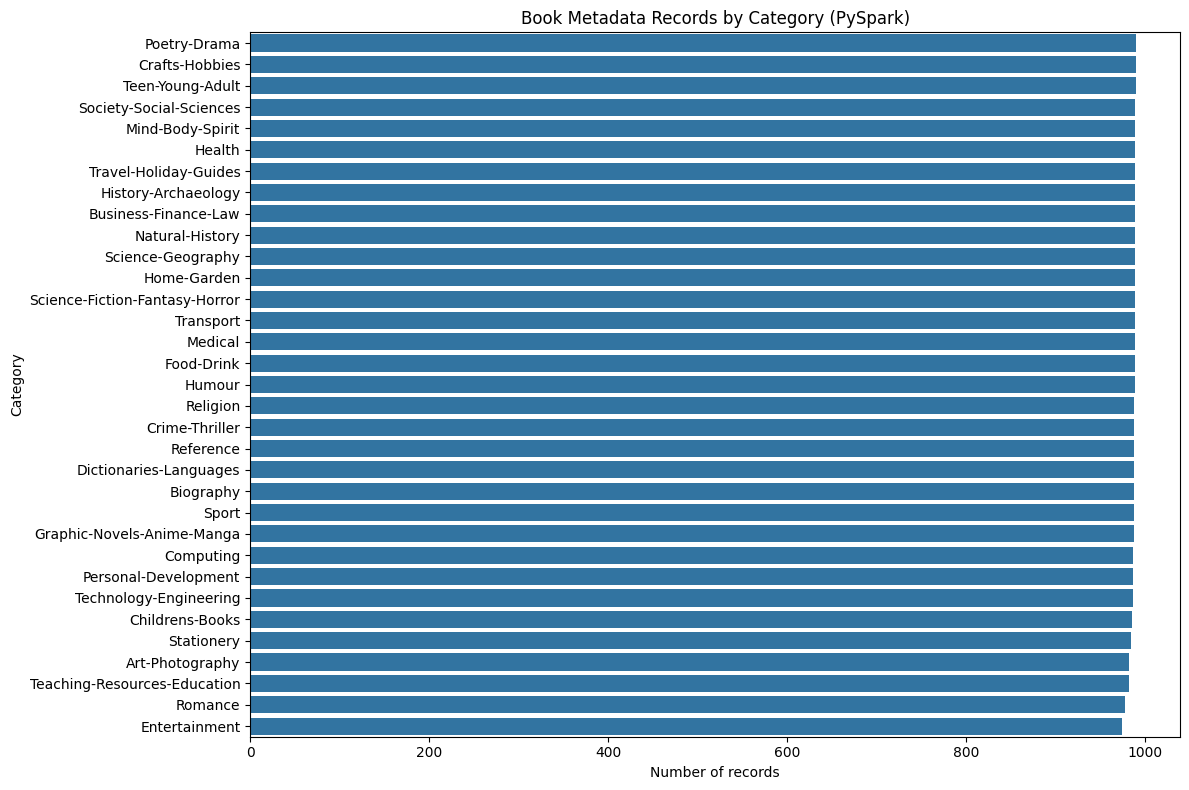

In [4]:
# Count null or blank values in each CSV column
total_rows = spark_df.count()

missing_exprs = [
    F.sum(
        F.when(
            F.col(c).isNull() | (F.trim(F.col(c).cast("string")) == ""),
            1
        ).otherwise(0)
    ).alias(c)
    for c in spark_df.columns
]

missing_values = spark_df.select(*missing_exprs)
print("Total rows:", total_rows)
missing_values.show(truncate=False)

# Inspect category values and frequencies in the CSV
if "category" in spark_df.columns:
    spark_category_counts = (
        spark_df.groupBy("category")
        .count()
        .orderBy(F.desc("count"))
    )
    spark_category_counts.show(50, truncate=False)

    category_plot_df = spark_category_counts.toPandas()
    plt.figure(figsize=(12, 8))
    sns.barplot(data=category_plot_df, y="category", x="count")
    plt.title("Book Metadata Records by Category (PySpark)")
    plt.xlabel("Number of records")
    plt.ylabel("Category")
    plt.tight_layout()
    plt.show()
else:
    raise ValueError("The CSV does not contain a 'category' column.")


Inspect the image-category folders

Number of category folders: 33
Category names:
- Art-Photography
- Biography
- Business-Finance-Law
- Childrens-Books
- Computing
- Crafts-Hobbies
- Crime-Thriller
- Dictionaries-Languages
- Entertainment
- Food-Drink
- Graphic-Novels-Anime-Manga
- Health
- History-Archaeology
- Home-Garden
- Humour
- Medical
- Mind-Body-Spirit
- Natural-History
- Personal-Development
- Poetry-Drama
- Reference
- Religion
- Romance
- Science-Fiction-Fantasy-Horror
- Science-Geography
- Society-Social-Sciences
- Sport
- Stationery
- Teaching-Resources-Education
- Technology-Engineering
- Teen-Young-Adult
- Transport
- Travel-Holiday-Guides
Total image files: 32581


,category,image_count
0,Art-Photography,982
1,Biography,988
2,Business-Finance-Law,989
3,Childrens-Books,986
4,Computing,987
5,Crafts-Hobbies,990
6,Crime-Thriller,988
7,Dictionaries-Languages,988
8,Entertainment,975
9,Food-Drink,989


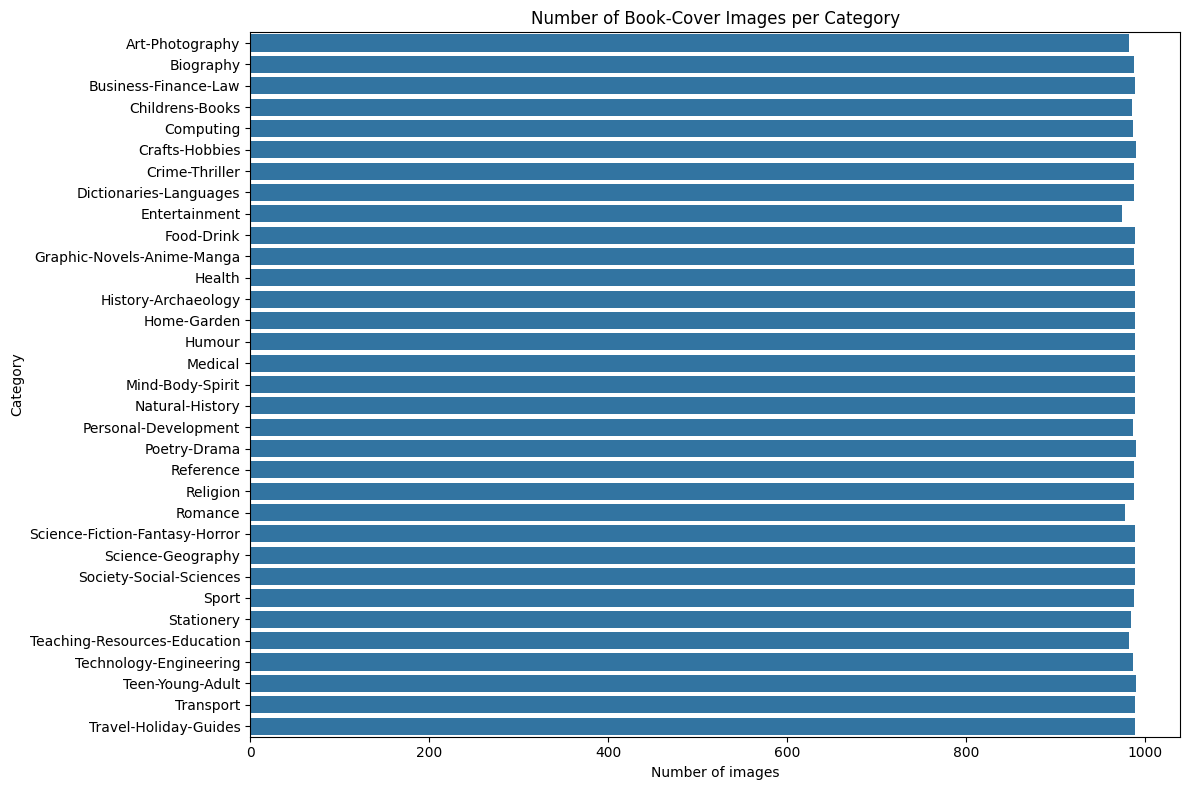

In [5]:
if not IMAGE_DIR.exists():
    raise FileNotFoundError(
        f"Image directory was not found: {IMAGE_DIR}\n"
        "Check that the extracted dataset contains a 'book-covers' folder."
    )

class_folders = sorted(
    p.name for p in IMAGE_DIR.iterdir() if p.is_dir()
)

if len(class_folders) == 0:
    raise ValueError("No category subfolders were found inside the book-covers folder.")

print("Number of category folders:", len(class_folders))
print("Category names:")
for name in class_folders:
    print("-", name)

image_extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
folder_counts = {}

for category in class_folders:
    folder = IMAGE_DIR / category
    folder_counts[category] = sum(
        1 for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    )

folder_count_df = pd.DataFrame({
    "category": list(folder_counts.keys()),
    "image_count": list(folder_counts.values())
}).sort_values("category")

print("Total image files:", int(folder_count_df["image_count"].sum()))
display(folder_count_df)

plt.figure(figsize=(12, 8))
sns.barplot(data=folder_count_df, y="category", x="image_count")
plt.title("Number of Book-Cover Images per Category")
plt.xlabel("Number of images")
plt.ylabel("Category")
plt.tight_layout()
plt.show()


Build the image index and validate image files

In [8]:
image_records = []
corrupt_images = []

for category in class_folders:
    category_folder = IMAGE_DIR / category

    for image_path in category_folder.iterdir():
        if not image_path.is_file() or image_path.suffix.lower() not in image_extensions:
            continue

        try:
            # Verify the image can be opened
            with Image.open(image_path) as img:
                img.verify()
            image_records.append({
                "image_path": str(image_path),
                "category": category
            })
        except (UnidentifiedImageError, OSError, ValueError):
            corrupt_images.append(str(image_path))

image_df = pd.DataFrame(image_records)

if image_df.empty:
    raise ValueError("No valid images were found. Check IMAGE_DIR and the image files.")

print("Valid images:", len(image_df))
print("Corrupt/unreadable images skipped:", len(corrupt_images))
print("Duplicate image paths:", image_df["image_path"].duplicated().sum())
print("Missing image paths:", image_df["image_path"].isna().sum())
print("Number of image classes:", image_df["category"].nunique())

display(image_df.head())


Valid images: 32581
Corrupt/unreadable images skipped: 0
Duplicate image paths: 0
Missing image paths: 0
Number of image classes: 33


,image_path,category
0,C:\Users\funga\Downloads\archive (15)\book-cov...,Art-Photography
1,C:\Users\funga\Downloads\archive (15)\book-cov...,Art-Photography
2,C:\Users\funga\Downloads\archive (15)\book-cov...,Art-Photography
3,C:\Users\funga\Downloads\archive (15)\book-cov...,Art-Photography
4,C:\Users\funga\Downloads\archive (15)\book-cov...,Art-Photography


Display sample book-cover images

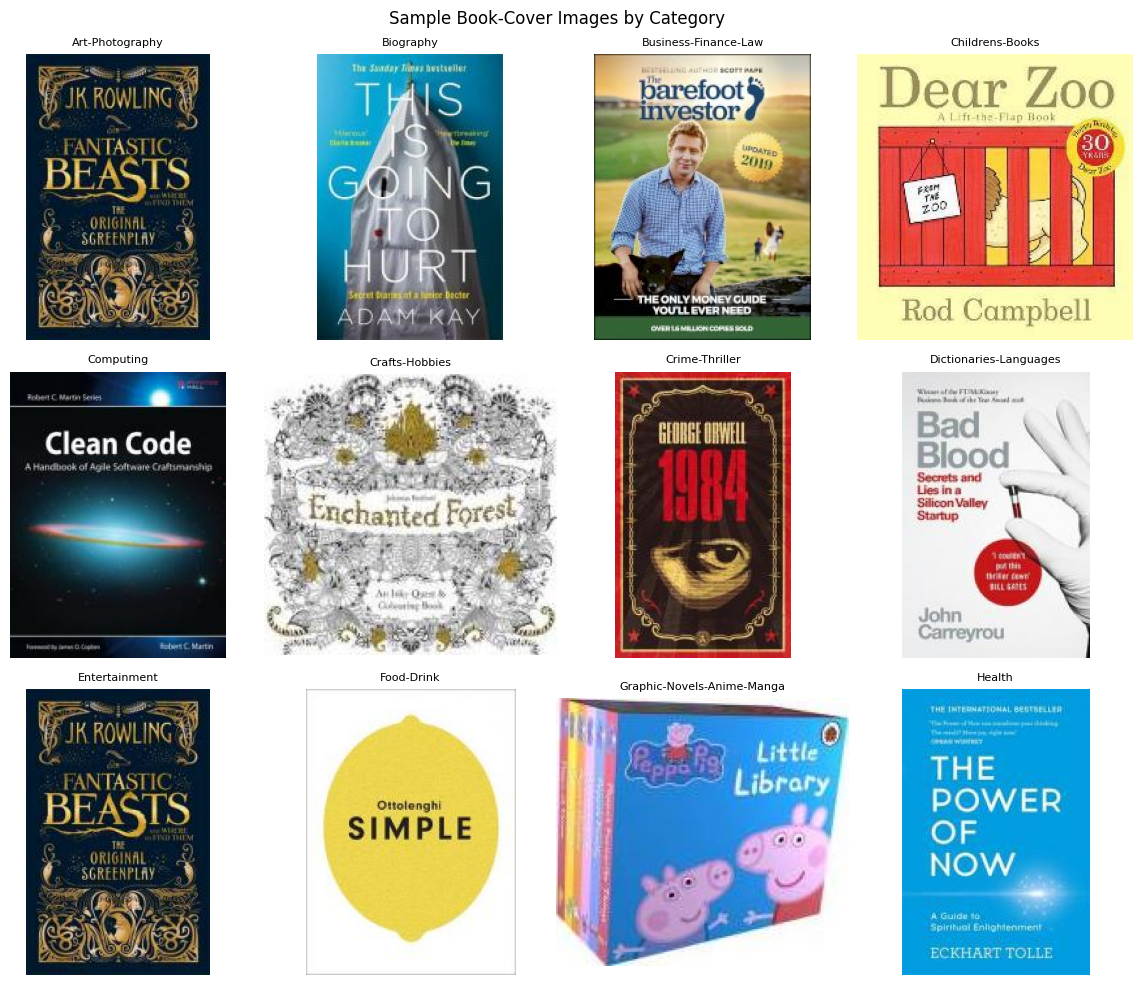

In [7]:
sample_df = image_df.groupby("category", group_keys=False).head(1).head(12)

fig, axes = plt.subplots(3, 4, figsize=(12, 10))
for ax, (_, row) in zip(axes.flat, sample_df.iterrows()):
    with Image.open(row["image_path"]) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(row["category"], fontsize=8)
    ax.axis("off")

for ax in axes.flat[len(sample_df):]:
    ax.axis("off")

plt.suptitle("Sample Book-Cover Images by Category")
plt.tight_layout()
plt.show()


Create stratified training, validation and test sets

In [9]:
class_names = sorted(image_df["category"].unique())
NUM_CLASSES = len(class_names)

train_df, remaining_df = train_test_split(
    image_df,
    test_size=0.30,
    random_state=SEED,
    stratify=image_df["category"]
)

val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    random_state=SEED,
    stratify=remaining_df["category"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Number of classes:", NUM_CLASSES)

assert set(train_df["category"]) == set(class_names)
assert set(val_df["category"]) == set(class_names)
assert set(test_df["category"]) == set(class_names)

split_counts = pd.DataFrame({
    "Training": train_df["category"].value_counts(),
    "Validation": val_df["category"].value_counts(),
    "Testing": test_df["category"].value_counts()
}).fillna(0).astype(int).sort_index()

display(split_counts)


Training images: 22806
Validation images: 4887
Testing images: 4888
Number of classes: 33


,Training,Validation,Testing
category,,,
Art-Photography,687,148,147
Biography,692,148,148
Business-Finance-Law,692,149,148
Childrens-Books,690,148,148
Computing,691,148,148
Crafts-Hobbies,693,148,149
Crime-Thriller,692,148,148
Dictionaries-Languages,692,148,148
Entertainment,683,146,146


In [ ]:
Encode category labels and create TensorFlow image datasets

In [10]:
class_to_index = {category: index for index, category in enumerate(class_names)}
index_to_class = {index: category for category, index in class_to_index.items()}

def load_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def create_dataset(dataframe, training=False):
    paths = dataframe["image_path"].astype(str).to_numpy()
    labels = dataframe["category"].map(class_to_index).astype("int32").to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(load_image, num_parallel_calls=AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)
    return dataset

train_dataset = create_dataset(train_df, training=True)
val_dataset = create_dataset(val_df)
test_dataset = create_dataset(test_df)

print("TensorFlow datasets created.")


TensorFlow datasets created.


Verify the image batches before training

In [11]:
for image_batch, label_batch in train_dataset.take(1):
    print("Image batch shape:", image_batch.shape)
    print("Label batch shape:", label_batch.shape)
    print("Minimum pixel value:", float(tf.reduce_min(image_batch).numpy()))
    print("Maximum pixel value:", float(tf.reduce_max(image_batch).numpy()))

    assert image_batch.shape[1:] == (128, 128, 3)
    assert tf.reduce_min(image_batch).numpy() >= 0.0
    assert tf.reduce_max(image_batch).numpy() <= 1.0


Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


Build and compile the CNN

In [12]:
tf.keras.backend.clear_session()

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()




Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 128, 128, 32)      864       
                                                                 
 batch_normalization (Batch  (None, 128, 128, 32)      128       
 Normalization)                                                  
                                                                 
 activation (Activation)     (None, 128, 128, 32)      0         
                                                                 
 max_pooling2d (MaxPooling2  (None, 64, 64, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 64, 64, 64)        18432     
                                                                 
 batch_normalization_1 (Bat  (None, 64, 64, 64)       

Train the CNN once

In [13]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/15


713/713 [==============================] - 459s 632ms/step - loss: 3.4972 - accuracy: 0.0459 - val_loss: 3.4309 - val_accuracy: 0.0643
Epoch 2/15
713/713 [==============================] - 456s 639ms/step - loss: 3.4361 - accuracy: 0.0598 - val_loss: 3.4048 - val_accuracy: 0.0694
Epoch 3/15
713/713 [==============================] - 332s 466ms/step - loss: 3.4068 - accuracy: 0.0690 - val_loss: 3.3893 - val_accuracy: 0.0771
Epoch 4/15
713/713 [==============================] - 837s 1s/step - loss: 3.3862 - accuracy: 0.0786 - val_loss: 3.3647 - val_accuracy: 0.0909
Epoch 5/15
713/713 [==============================] - 598s 833ms/step - loss: 3.3652 - accuracy: 0.0831 - val_loss: 3.3526 - val_accuracy: 0.0868
Epoch 6/15
713/713 [==============================] - 664s 931ms/step - loss: 3.3444 - accuracy: 0.0894 - val_loss: 3.3303 - val_accuracy: 0.1060
Epoch 7/15
713/713 [==============================] - 319s 447ms/step - loss: 3.3069 - accuracy: 0.0997 - val_loss: 3.2798 - 

Evaluate the final model on the unseen test set

In [14]:
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)

print("FINAL TEST RESULTS")
print("Test loss:", round(float(test_loss), 4))
print("Test accuracy:", round(float(test_accuracy) * 100, 2), "%")
print("Random-choice reference for balanced classes:", round(100 / NUM_CLASSES, 2), "%")


153/153 [==============================] - 22s 143ms/step - loss: 3.2167 - accuracy: 0.1203
FINAL TEST RESULTS
Test loss: 3.2167
Test accuracy: 12.03 %
Random-choice reference for balanced classes: 3.03 %


Generate predictions and the classification report

In [15]:
y_true = np.concatenate([
    labels.numpy() for images, labels in test_dataset
])

y_prob = model.predict(test_dataset, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    zero_division=0
))


153/153 [==============================] - 29s 166ms/step
                                precision    recall  f1-score   support

               Art-Photography       0.12      0.03      0.05       147
                     Biography       0.10      0.09      0.10       148
          Business-Finance-Law       0.13      0.36      0.19       148
               Childrens-Books       0.16      0.09      0.11       148
                     Computing       0.17      0.18      0.17       148
                Crafts-Hobbies       0.13      0.17      0.15       149
                Crime-Thriller       0.12      0.47      0.19       148
        Dictionaries-Languages       0.12      0.07      0.09       148
                 Entertainment       0.13      0.03      0.05       146
                    Food-Drink       0.16      0.08      0.11       149
    Graphic-Novels-Anime-Manga       0.24      0.32      0.27       148
                        Health       0.08      0.18      0.11       149
     

Plot training and validation accuracy

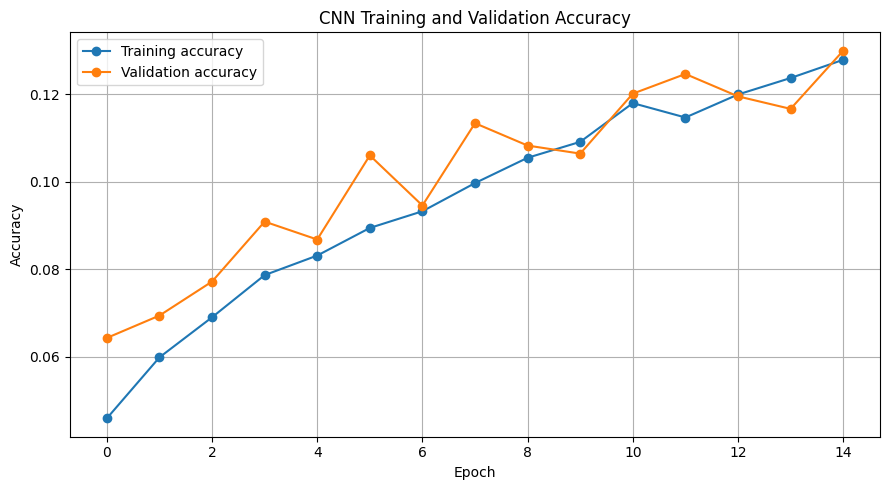

In [16]:
plt.figure(figsize=(9, 5))
plt.plot(history.history["accuracy"], marker="o", label="Training accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Plot training and validation loss

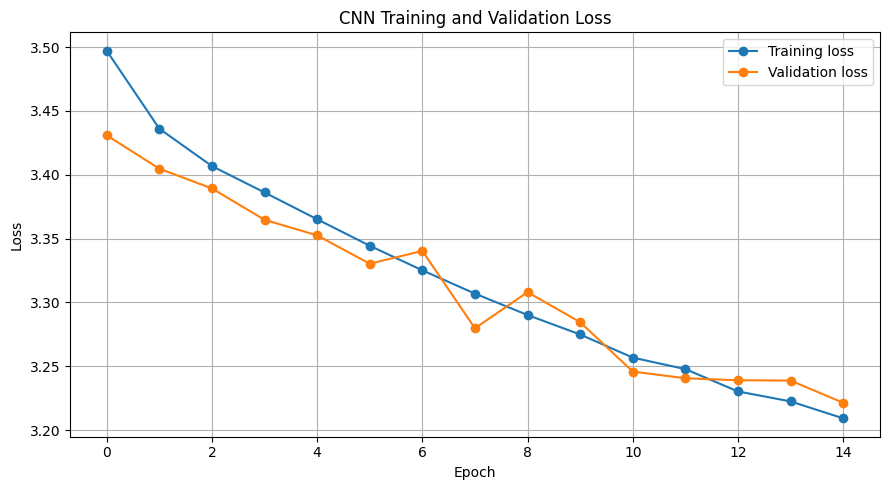

In [17]:
plt.figure(figsize=(9, 5))
plt.plot(history.history["loss"], marker="o", label="Training loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation loss")
plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Display the confusion matrix

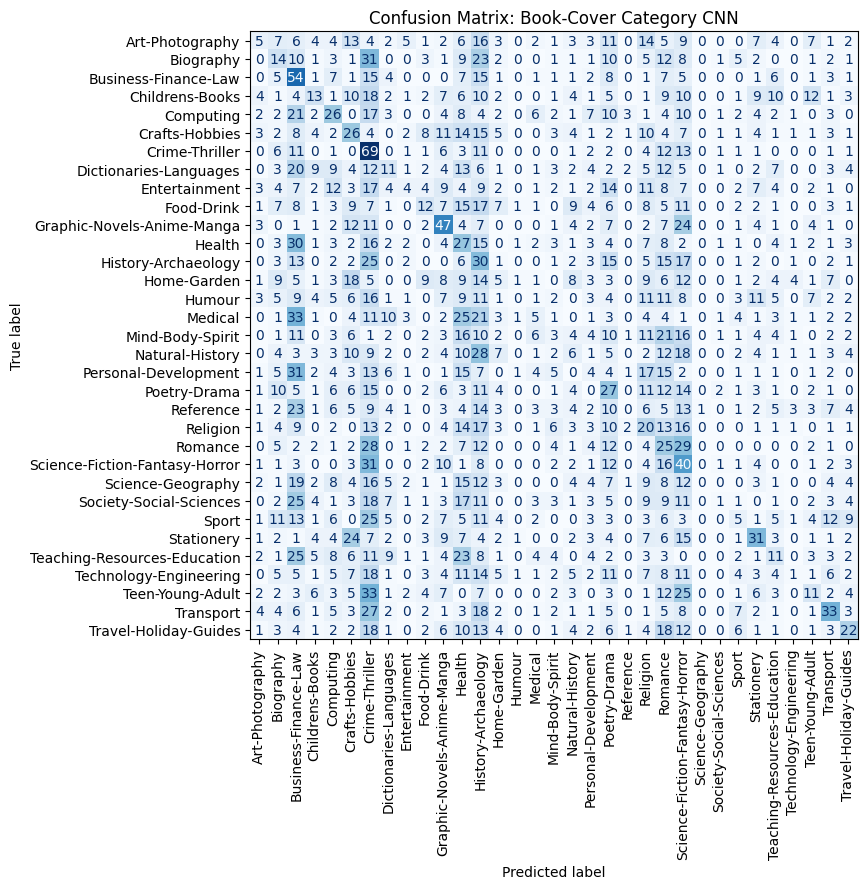

In [19]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

fig, ax = plt.subplots(figsize=(9, 9))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)
plt.title("Confusion Matrix: Book-Cover Category CNN")
plt.tight_layout()
plt.show()


Save the trained model and category mapping

In [20]:
PROJECT_DIR = Path(r"C:\Users\funga\CNN_POE_Project")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

model_path = PROJECT_DIR / "book_cover_cnn_model.keras"
labels_path = PROJECT_DIR / "book_category_labels.json"

model.save(model_path)

with open(labels_path, "w", encoding="utf-8") as file:
    json.dump(class_names, file, indent=4)

print("Model saved to:", model_path)
print("Class labels saved to:", labels_path)


Model saved to: C:\Users\funga\CNN_POE_Project\book_cover_cnn_model.keras
Class labels saved to: C:\Users\funga\CNN_POE_Project\book_category_labels.json
